EDA Retail Sales Analysis

In [40]:
# Importing required Python Labraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [11]:
# Loadiing data set
df = pd.read_csv("OnlineRetail.csv", encoding="cp1252")

# Performing Initial Inspection on Data Set
print(df.shape)
df.isnull().sum()

(541909, 8)


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [12]:
df['Description'] = df['Description'].fillna('Unknown')
print(df[['Description', 'CustomerID']].isnull().sum())
print("Dataset shape:", df.shape)


Description         0
CustomerID     135080
dtype: int64
Dataset shape: (541909, 8)


The `Description` column has 1,454 missing values, which are replaced with "Unknown" because they are not essential for RFM  analysis. The `CustomerID` column has 135,080 missing values, which are kept unchanged to avoid data loss. However, these transactions cannot be used for customer-level RFM analysis.

In [20]:
#Desciptive Analysis

df['Sales'] = df['Quantity'] * df['UnitPrice']
total_sales = df['Sales'].sum()
print("Total Sales:", round(total_sales, 2))
average_purchase = df.groupby('InvoiceNo')['Sales'].sum().mean()
print("Average Purchase Value:", round(average_purchase, 2))
total_transactions = df['InvoiceNo'].nunique()
print("Total Transactions:", total_transactions)
total_customers = df['CustomerID'].nunique()
print("Unique Customers:", total_customers)
purchase_frequency = (df.dropna(subset=['CustomerID']).groupby('CustomerID')['InvoiceNo'].nunique())
print("Average Purchase Frequency:",round(purchase_frequency.mean(), 2))
customer_df = df.dropna(subset=['CustomerID']).copy()
customer_df['Sales'] = (customer_df['Quantity'] * customer_df['UnitPrice'])
customer_spending = (customer_df.groupby('CustomerID')['Sales'].sum())
average_customer_spending = customer_spending.mean()
print("Average Customer Lifetime Value:", round(average_customer_spending, 2))

Total Sales: 9747747.93
Average Purchase Value: 376.36
Total Transactions: 25900
Unique Customers: 4372
Average Purchase Frequency: 5.08
Average Customer Lifetime Value: 1898.46


In [21]:
# Create a clean customer-level dataset
rfm_df = df.dropna(subset=['CustomerID']).copy()
# Convert dates to datetime
rfm_df['InvoiceDate'] = pd.to_datetime(rfm_df['InvoiceDate'], errors='coerce')
# Remove rows with invalid dates
rfm_df = rfm_df.dropna(subset=['InvoiceDate'])
# Calculate sales for each item
rfm_df['Sales'] = rfm_df['Quantity'] * rfm_df['UnitPrice']
# Reference date: one day after the last transaction
reference_date = rfm_df['InvoiceDate'].max() + pd.Timedelta(days=1)
# Calculate RFM for each customer
rfm = rfm_df.groupby('CustomerID').agg(Recency=('InvoiceDate',lambda x: (reference_date - x.max()).days),Frequency=('InvoiceNo', 'nunique'),Monetary=('Sales', 'sum'))
rfm.head()


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,2,0.00
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [23]:
# select features
features = rfm[['Recency', 'Frequency', 'Monetary']]
print(features.head())
print(features.isnull().sum())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          2      0.00
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
Recency      0
Frequency    0
Monetary     0
dtype: int64


In [25]:
# Standardise the RFM features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])

In [26]:
# Convert the scaled data into a DataFrame
rfm_scaled = pd.DataFrame(rfm_scaled,columns=['Recency', 'Frequency', 'Monetary'],index=rfm.index)

In [27]:
print("Feature means:")
print(rfm_scaled.mean().round(2))

print("\nFeature standard deviations:")
print(rfm_scaled.std(ddof=0).round(2))

Feature means:
Recency     -0.0
Frequency    0.0
Monetary     0.0
dtype: float64

Feature standard deviations:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


/lib/python3.14/site-packages/threadpoolctl.py:1135: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


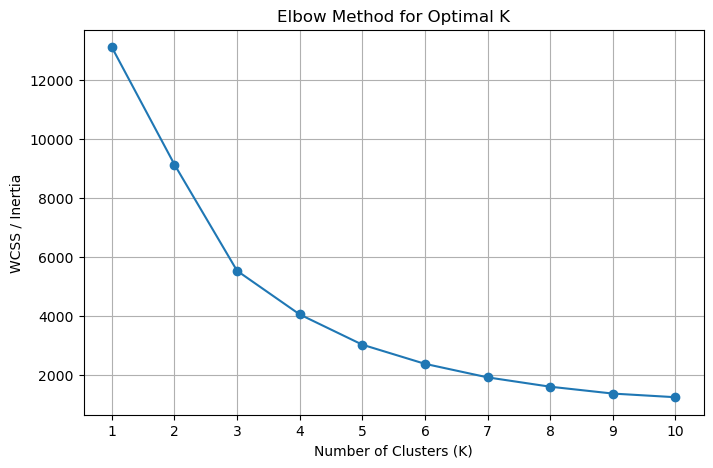

In [29]:
# Calculate WCSS for different numbers of clusters
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


Elbow Method graph shows that the curve starts to bend around K = 3. After K = 3, the
decrease in WCSS becomes slower, so 3 clusters is a reasonable starting choice


In [31]:
optimal_k = 3
# Train the K-Means model
kmeans = KMeans(n_clusters=optimal_k,random_state=42,n_init=10)
# Assign a cluster to each customer
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)
print(rfm[['Recency', 'Frequency', 'Monetary', 'Cluster']].head())
print("\nCustomers per cluster:")
print(rfm['Cluster'].value_counts().sort_index())

            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346.0         326          2      0.00        1
12347.0           2          7   4310.00        0
12348.0          75          4   1797.24        0
12349.0          19          1   1757.55        0
12350.0         310          1    334.40        1

Customers per cluster:
Cluster
0    3244
1    1105
2      23
Name: count, dtype: int64


In [32]:
cluster_summary = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
print(cluster_summary)

         Recency  Frequency  Monetary
Cluster                              
0          40.09       5.60   1821.84
1         246.37       1.85    459.54
2           6.09      86.87  81835.86


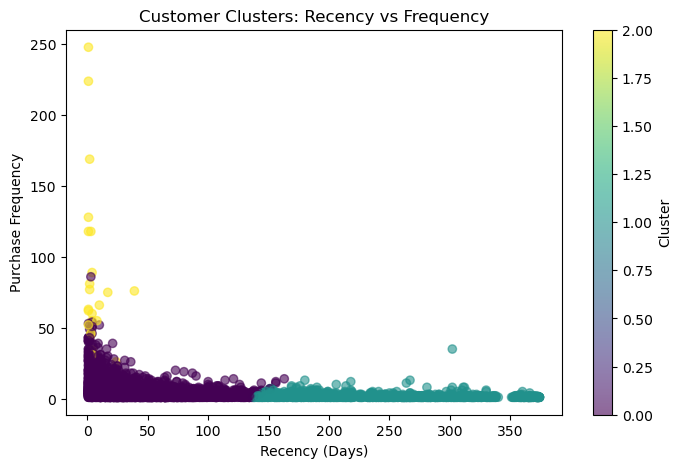

In [33]:
#Visualise clusters using scatter plots
plt.figure(figsize=(8, 5))
plt.scatter(
    rfm['Recency'],
    rfm['Frequency'],
    c=rfm['Cluster'],
    cmap='viridis',
    alpha=0.6
)

plt.title('Customer Clusters: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')
plt.colorbar(label='Cluster')
plt.show()


Customers with lower Recency values purchased more recently. Higher Frequency
values indicate more frequent purchases. Different colors represent the three clusters.

In [34]:
#calculate mean feature values per cluster
cluster_profile = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
print(cluster_profile)

         Recency  Frequency  Monetary
Cluster                              
0          40.09       5.60   1821.84
1         246.37       1.85    459.54
2           6.09      86.87  81835.86


In [35]:
#describe the customer type
customer_type = {
    0: 'Regular Customers',
    1: 'At-Risk Customers',
    2: 'High-Value Customers'
}
rfm['Customer_Type'] = rfm['Cluster'].map(customer_type)
print(rfm[['Recency', 'Frequency', 'Monetary',
           'Cluster', 'Customer_Type']].head())

            Recency  Frequency  Monetary  Cluster      Customer_Type
CustomerID                                                          
12346.0         326          2      0.00        1  At-Risk Customers
12347.0           2          7   4310.00        0  Regular Customers
12348.0          75          4   1797.24        0  Regular Customers
12349.0          19          1   1757.55        0  Regular Customers
12350.0         310          1    334.40        1  At-Risk Customers


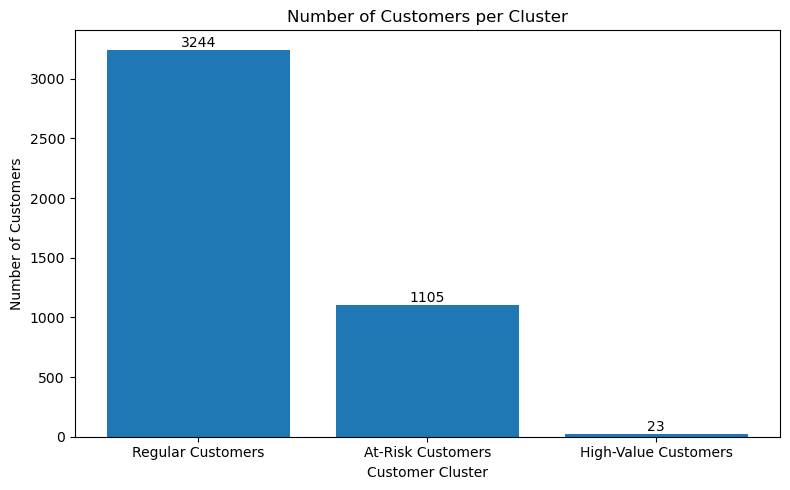

In [39]:
cluster_counts = rfm['Cluster'].value_counts().sort_index()

# bar chart
plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index, cluster_counts.values)

plt.title('Number of Customers per Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.xticks([0, 1, 2], ['Regular Customers',
                       'At-Risk Customers',
                       'High-Value Customers'])

# Show customer counts above bars
for x, y in zip(cluster_counts.index, cluster_counts.values):
    plt.text(x, y, str(y), ha='center', va='bottom')

plt.tight_layout()
plt.show()

The bar chart shows the distribution of customers across the three clusters identified using the K-Means clustering algorithm. Each bar represents the number of customers in a specific segment: Regular Customers, At-Risk Customers, and High-Value Customers. This visualization helps identify the largest and smallest customer segments and supports businesses in planning targeted marketing strategies to improve customer retention and sales.

# Insights section:
Based on the RFM analysis and K-Means clustering results, I recommend the following marketing strategies:

Regular Customers (Cluster 0):Introduce loyalty programs, personalized recommendations, and repeat-purchase 
discounts to increase purchase frequency and spending.
At-Risk Customers (Cluster 1):Use re-engagement campaigns, special offers, and feedback surveys to encourage
inactive customers to return.
High-Value Customers (Cluster 2):Provide VIP rewards, exclusive offers, early access to new products, and 
personalized services to maintain customer loyalty.

These targeted marketing strategies can help the business improve customer retention, increase sales, and
use its marketing budget more effectively.